# Chunk 48 — Deep single-band S11 figures in the 2.5–3.0 GHz window (figures only)

Same models, test sets, harness, band definition and selection rule as Chunk 46, restricted to a narrower group of antennas.

**Which antennas qualify (pre-registered, applied to the TRUE curve of each test antenna):**
1. **Single band:** exactly one dip below −10 dB with ≥ 3 dB prominence, using Chunk 46's band rule (dips ≥ 150 MHz apart).
2. **Deep:** that dip goes below **−20 dB**.
3. **In the window:** that dip's frequency lies in **2.5–3.0 GHz** (inclusive).

**Example selection:** as in Chunk 46, the qualifying test antenna whose **fine-tuned prediction is the most accurate** (lowest MSE by default; `SELECT_METRIC` in cell 3). The figure is a best-case example. Its caption names the group size and the group's median error.

**Grids:** 12, 15, 25, 35, 45 (55×55 excluded). The 2.5–3.0 GHz band is rare (most resonances sit at 3.5–3.9 GHz), so a small test set may have **no** qualifying antenna:
- That grid's figure is then skipped, never forced. The constraints are not loosened.
- A filter funnel shows how many antennas pass each step per grid.
- A near-miss table lists the closest non-qualifying antennas, for information only.

**Models:**
- **Fine-tuned:** the Chunk 44 five-grid replay model `ch44_ft15_from4_replay_p100_s0.pt`.
- **Zero-shot:** `best_model.pt`, trained on 25×25 only. It is not drawn at 25×25, where it is in-distribution, as in Chunk 46.

**Harness:** both models' test MSE on every grid must reproduce Chunk 44 before anything is plotted.

**Rules:** no training, and no model or threshold choices made on test data.

**Writes:**
- `figures/ch48/ch48_{N}x{N}_single_band_deep_2p5_3p0.{pdf,png}`
- `ch48_selected_examples.csv`, `ch48_funnel.csv`, `ch48_near_misses.csv`, `ch48_captions.md`

## 1. Installs

In [1]:
!apt-get -qq install -y fonts-liberation > /dev/null 2>&1
!pip -q install torch_geometric pyarrow tabulate

## 2. Repository and Drive

In [2]:
import os, sys, subprocess
REPO_ROOT = '/content/antenna_gnn'
if os.path.isdir(f'{REPO_ROOT}/.git'):
    subprocess.run(['git', '-C', REPO_ROOT, 'pull', '-q'], check=True)
else:
    subprocess.run(['git', 'clone', '-q', 'https://github.com/asparagusD/antenna_gnn.git', REPO_ROOT], check=True)
sys.path.insert(0, f'{REPO_ROOT}/src')
from google.colab import drive
drive.mount('/content/drive')
DATA_ROOT = '/content/drive/MyDrive/antenna_gnn'
ART, CKPT, SPLITS, LOCAL = f'{DATA_ROOT}/artifacts', f'{DATA_ROOT}/checkpoints', f'{DATA_ROOT}/splits', '/content/local_graphs'
os.makedirs(LOCAL, exist_ok=True)
print(REPO_ROOT, DATA_ROOT)

Mounted at /content/drive
/content/antenna_gnn /content/drive/MyDrive/antenna_gnn


## 3. Setup
**What it sets:**
- **Models and grids:** as in Chunk 46.
- **Band rule:** Chunk 46's, unchanged.
- **The two new constraints:** `DEPTH_DB = −20` and the frequency window `F_LO`–`F_HI` = 2.5–3.0 GHz.
- **Selection metric:** MSE, as in Chunk 46.
- **Figure style:** Chunk 46's (IEEE single column, 8 pt Times-compatible serif, colour-blind-safe palette with distinct line styles).

The constraints are fixed here, before any test curve is read.

In [3]:
# ── Setup: models, constraints, selection rule, figure style ──
import json, glob, hashlib, zipfile, shutil
from pathlib import Path
import numpy as np, pandas as pd, torch
from scipy.signal import find_peaks
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as GeoLoader
import matplotlib, matplotlib.pyplot as plt
from matplotlib import font_manager
from tqdm.auto import tqdm
from model import AntennaGNN
from feed_component import AppendFeedComponentFeature

# Models (as Chunk 46). Change MODEL_FT/FT_ID to plot another checkpoint; the harness then has no Chunk 44 reference.
MODEL_FT = f'{CKPT}/ch44_ft15_from4_replay_p100_s0.pt'; FT_ID = 'ft15_from4_replay_p100_s0'
MODEL_ZS = f'{CKPT}/best_model.pt'
GRIDS = (25, 12, 15, 35, 45)            # drop a grid here to skip it
F = np.linspace(1, 4, 201); TAU = -10.0
BAND = dict(height=10.0, prominence=3.0, distance=10)   # Chunk 46 band rule, unchanged

# ── Chunk 48 constraints (pre-registered; never loosened after seeing test data) ──
DEPTH_DB = -15.0                       # the single dip must go BELOW this (true curve)
F_LO, F_HI = 3.5, 3.75                 # the single dip's frequency must lie in [F_LO, F_HI] GHz, inclusive
F_TOL = 1e-9                           # float tolerance on the window edges (2.5 GHz is exactly a grid point)
SELECT_METRIC = 'mse'                  # 'mse' (dB²) or 'mae' (dB): the error used to rank fine-tuned predictions
TAG = f'single_band_deep_{F_LO:.2f}_{F_HI:.2f}'.replace('.', 'p')   # -> single_band_deep_3p50_3p75

FIG = f'{DATA_ROOT}/figures/ch48'; os.makedirs(FIG, exist_ok=True)
def OUT(n):
    assert n.startswith('ch48_'), n; return f'{ART}/{n}'
PRIOR = {p: os.path.getmtime(p) for pat in (f'{ART}/*', f'{CKPT}/*.pt') for p in glob.glob(pat)
         if os.path.isfile(p) and not Path(p).name.startswith('ch48_')}
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False
MEAN = torch.tensor(np.load(f'{ART}/s11_mean.npy'), dtype=torch.float32, device=DEVICE)   # read only
STD = torch.tensor(np.load(f'{ART}/s11_std.npy'), dtype=torch.float32, device=DEVICE)

FONT = next((f for f in ('Times New Roman', 'Liberation Serif', 'DejaVu Serif')
             if any(f == x.name for x in font_manager.fontManager.ttflist)), 'serif')
matplotlib.rcParams.update({'font.family': 'serif', 'font.serif': [FONT], 'font.size': 8, 'axes.labelsize': 8,
                            'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 7, 'axes.linewidth': 0.6,
                            'axes.grid': True, 'grid.alpha': 0.3, 'grid.linewidth': 0.5, 'pdf.fonttype': 42,
                            'ps.fonttype': 42, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02, 'mathtext.fontset': 'stix'})
STYLE = {'gt': dict(color='#000000', lw=1.3, ls='-', label='Ground truth'),
         'zs': dict(color='#E69F00', lw=1.1, ls=':', label='Zero-shot (trained on 25×25 only)'),
         'ft': dict(color='#0072B2', lw=1.1, ls='--', label='Prediction after replay-based fine-tuning')}
print(f'font: {FONT} | figures -> {FIG}')
print(f'constraints: single band, dip < {DEPTH_DB:.1f} dB, dip frequency in [{F_LO}, {F_HI}] GHz | select by lowest {SELECT_METRIC.upper()}')

font: Liberation Serif | figures -> /content/drive/MyDrive/antenna_gnn/figures/ch48
constraints: single band, dip < -15.0 dB, dip frequency in [3.5, 3.75] GHz | select by lowest MSE


## 4. Test sets and graphs
Same as Chunk 46: test splits for the five grids, staged graphs.

In [4]:
# ── Test splits and graphs (as Chunk 46) ──
def pairs(v):
    if isinstance(v, dict):
        return {(int(g), int(i)) for g, x in v.items() for i in x}
    return {(int(e[0]), int(e[1])) for e in v}
TEST = {25: sorted(i for g, i in pairs(json.load(open(f'{SPLITS}/indices.json'))['test']) if g == 25)}
ft = pairs(json.load(open(f'{SPLITS}/finetune_test_indices.json')))
for N in (35, 45):
    TEST[N] = sorted(i for g, i in ft if g == N)
for N in (12, 15):
    TEST[N] = sorted(i for g, i in pairs(json.load(open(f'{SPLITS}/finetune{N}_test_indices.json'))))
for N in GRIDS:
    d = f'{LOCAL}/{N}x{N}'
    if not os.path.exists(f'{d}/_STAGED.txt'):
        os.makedirs(d, exist_ok=True)
        with zipfile.ZipFile(f'{DATA_ROOT}/data/processed/processed_{N}x{N}.zip') as Z:
            mem = [m for m in Z.namelist() if m.endswith('.pt')]
            for m in tqdm(mem, desc=f'stage {N}x{N}', leave=False):
                with Z.open(m) as a, open(f'{d}/{os.path.basename(m)}', 'wb') as b:
                    shutil.copyfileobj(a, b)
        open(f'{d}/_STAGED.txt', 'w').write(str(len(mem)))
    print(f'{N}x{N}: {len(TEST[N]):,} test antennas')
TRANSFORM = AppendFeedComponentFeature()
def load(N, i):
    d = torch.load(f'{LOCAL}/{N}x{N}/sample_{int(i)}.pt', weights_only=False)
    assert d.x.shape == (N * N + 1, 5) and float(d.x[-1, 3]) == -1.0 and d.y.numel() == 201
    return d

stage 25x25:   0%|          | 0/99833 [00:00<?, ?it/s]

25x25: 9,983 test antennas


stage 12x12:   0%|          | 0/7000 [00:00<?, ?it/s]

12x12: 700 test antennas


stage 15x15:   0%|          | 0/6367 [00:00<?, ?it/s]

15x15: 637 test antennas


stage 35x35:   0%|          | 0/4988 [00:00<?, ?it/s]

35x35: 499 test antennas


stage 45x45:   0%|          | 0/6984 [00:00<?, ?it/s]

45x45: 699 test antennas


## 5. Predictions and harness
Runs both models on every test antenna of every grid, in raw dB. **Asserts each model's test MSE reproduces Chunk 44** to within 0.005 dB², as in Chunk 46.

In [5]:
# ── Models: predictions for every test antenna of every grid (as Chunk 46) ──
def gnn(nf):
    return AntennaGNN(node_feat_dim=nf, edge_feat_dim=2, hidden_dim=128, heads=8, edge_dim=16, num_blocks=4, output_dim=201)
def state_of(path):
    c = torch.load(path, map_location='cpu', weights_only=False)
    s = c['model_state'] if isinstance(c, dict) and 'model_state' in c else c
    return {k[7:] if k.startswith('module.') else k: v for k, v in s.items()}
FT = gnn(6); FT.load_state_dict(state_of(MODEL_FT), strict=True); FT = FT.to(DEVICE).eval()
ZS = gnn(5); ZS.load_state_dict(state_of(MODEL_ZS), strict=True); ZS = ZS.to(DEVICE).eval()
assert sum(p.numel() for p in FT.parameters()) == 587_129 and sum(p.numel() for p in ZS.parameters()) == 587_001
@torch.no_grad()
def run(N, ids, bs=128):
    T, P_ft, P_zs = [], [], []
    for s in tqdm(range(0, len(ids), bs), desc=f'Run {N}x{N}', leave=False):
        ds = [load(N, i) for i in ids[s:s + bs]]
        T.append(np.stack([d.y.reshape(-1).numpy() for d in ds]))
        b5 = next(iter(GeoLoader([Data(x=d.x, edge_index=d.edge_index, edge_attr=d.edge_attr) for d in ds], batch_size=len(ds)))).to(DEVICE)
        b6 = next(iter(GeoLoader([TRANSFORM(Data(x=d.x.clone(), edge_index=d.edge_index, edge_attr=d.edge_attr)) for d in ds],
                                 batch_size=len(ds)))).to(DEVICE)
        P_zs.append((ZS(b5) * STD + MEAN).double().cpu().numpy()); P_ft.append((FT(b6) * STD + MEAN).double().cpu().numpy())
    return np.concatenate(T).astype(np.float64), np.concatenate(P_ft), np.concatenate(P_zs)
RES = {N: run(N, TEST[N]) for N in tqdm(GRIDS, desc='predict test sets')}

# Harness: the plotted models must reproduce the test MSEs recorded in Chunk 44 (same checkpoints, same test sets).
M44 = pd.read_csv(f'{ART}/ch44_metrics.csv')
for N in GRIDS:
    T, Pf, Pz = RES[N]
    for mid, P in ((FT_ID, Pf), ('best_model', Pz)):
        r = M44[(M44.model_id == mid) & (M44.grid == N) & (M44.metric == 'mse_db2')]
        v = float(((P - T) ** 2).mean())
        if len(r):
            assert abs(v - r.estimate.iloc[0]) < 0.005, f'STOP: {mid} {N}x{N} test MSE {v:.4f} differs from Chunk 44 ({r.estimate.iloc[0]:.4f})'
        print(f'{N}x{N} {mid:28s} test MSE {v:.3f} dB²' + (f'  (Chunk 44: {r.estimate.iloc[0]:.3f})' if len(r) else '  (not in Chunk 44; MODEL_FT changed?)'))

predict test sets:   0%|          | 0/5 [00:00<?, ?it/s]

Run 25x25:   0%|          | 0/78 [00:00<?, ?it/s]

Run 12x12:   0%|          | 0/6 [00:00<?, ?it/s]

Run 15x15:   0%|          | 0/5 [00:00<?, ?it/s]

Run 35x35:   0%|          | 0/4 [00:00<?, ?it/s]

Run 45x45:   0%|          | 0/6 [00:00<?, ?it/s]

25x25 ft15_from4_replay_p100_s0    test MSE 1.391 dB²  (Chunk 44: 1.391)
25x25 best_model                   test MSE 1.318 dB²  (Chunk 44: 1.318)
12x12 ft15_from4_replay_p100_s0    test MSE 1.812 dB²  (Chunk 44: 1.812)
12x12 best_model                   test MSE 5.035 dB²  (Chunk 44: 5.035)
15x15 ft15_from4_replay_p100_s0    test MSE 2.106 dB²  (Chunk 44: 2.106)
15x15 best_model                   test MSE 4.695 dB²  (Chunk 44: 4.695)
35x35 ft15_from4_replay_p100_s0    test MSE 1.128 dB²  (Chunk 44: 1.128)
35x35 best_model                   test MSE 2.529 dB²  (Chunk 44: 2.529)
45x45 ft15_from4_replay_p100_s0    test MSE 1.125 dB²  (Chunk 44: 1.125)
45x45 best_model                   test MSE 3.691 dB²  (Chunk 44: 3.691)


## 6. Filter, funnel and example selection
**What it does, per grid:**
1. Classifies every **true** test curve with Chunk 46's band rule and keeps the single-band ones.
2. For each single-band antenna, reads its dip depth and frequency at the detected dip.
3. Applies the two constraints: dip < −20 dB and dip frequency in 2.5–3.0 GHz.
4. Prints the **funnel**, the count left after each step.
5. Picks the qualifying antenna with the **most accurate fine-tuned prediction**, exactly as Chunk 46.

**If a grid has no qualifying antenna:**
- Its figure is skipped. The constraints are not loosened.
- The **near-miss** table lists, for information only:
  - the deepest single-band antennas inside the window that miss −20 dB
  - the deep single-band antennas closest to the window

**Writes:** `ch48_funnel.csv`, `ch48_selected_examples.csv`, `ch48_near_misses.csv`.

In [6]:
# ── Filter the TRUE curves, report the funnel, select the most accurate fine-tuned prediction per grid ──
def n_bands(y):
    pk, _ = find_peaks(-y, **BAND)
    return len(pk), pk
SEL, FUNNEL, NEAR = [], [], []
for N in GRIDS:
    T, Pf, Pz = RES[N]
    rows = np.arange(len(T))
    bands = [n_bands(t) for t in T]
    single = np.array([b[0] == 1 for b in bands])
    dip_i = np.array([b[1][0] if b[0] == 1 else 0 for b in bands])          # index of the single dip (0 = placeholder)
    dip_db = np.where(single, T[rows, dip_i], np.nan)                      # true depth at the dip
    dip_f = np.where(single, F[dip_i], np.nan)                             # true frequency of the dip
    deep = single & (dip_db < DEPTH_DB)
    in_win = single & (dip_f >= F_LO - F_TOL) & (dip_f <= F_HI + F_TOL)
    ok = deep & in_win
    mse_ft = ((Pf - T) ** 2).mean(1); mae_ft = np.abs(Pf - T).mean(1)
    mse_zs = ((Pz - T) ** 2).mean(1); mae_zs = np.abs(Pz - T).mean(1)
    err = mse_ft if SELECT_METRIC == 'mse' else mae_ft
    FUNNEL.append(dict(grid=N, n_test=len(T), single_band=int(single.sum()), single_and_deep=int(deep.sum()),
                       single_and_in_window=int(in_win.sum()), qualifying=int(ok.sum())))
    grp = np.flatnonzero(ok)
    if len(grp) == 0:
        print(f'WARNING: no {N}x{N} test antenna is single band, below {DEPTH_DB:.0f} dB and in {F_LO}-{F_HI} GHz; figure skipped')
        miss_depth = np.flatnonzero(in_win & ~deep); miss_depth = miss_depth[np.argsort(dip_db[miss_depth])][:3]
        dist = np.maximum(F_LO - dip_f, dip_f - F_HI)
        miss_freq = np.flatnonzero(deep & ~in_win); miss_freq = miss_freq[np.argsort(dist[miss_freq])][:3]
        for kind, idx in (('in window, too shallow', miss_depth), ('deep enough, outside window', miss_freq)):
            for j in idx:
                NEAR.append(dict(grid=N, kind=kind, local_idx=TEST[N][j], dip_ghz=float(dip_f[j]), dip_db=float(dip_db[j]),
                                 mse_ft=float(mse_ft[j]), mae_ft=float(mae_ft[j])))
        continue
    j = grp[np.argmin(err[grp])]                                           # the most accurate fine-tuned prediction
    SEL.append(dict(grid=N, local_idx=TEST[N][j], row=int(j), group_size=len(grp),
                    dip_ghz=float(dip_f[j]), dip_db=float(dip_db[j]),
                    ft_pred_min_ghz=float(F[np.argmin(Pf[j])]), ft_pred_min_db=float(Pf[j].min()),
                    zs_pred_min_ghz=float(F[np.argmin(Pz[j])]), zs_pred_min_db=float(Pz[j].min()),
                    mse_ft=float(mse_ft[j]), mae_ft=float(mae_ft[j]), mse_zs=float(mse_zs[j]), mae_zs=float(mae_zs[j]),
                    group_median_mse_ft=float(np.median(mse_ft[grp])), group_median_mae_ft=float(np.median(mae_ft[grp])),
                    group_median_mse_zs=float(np.median(mse_zs[grp])), group_median_mae_zs=float(np.median(mae_zs[grp])),
                    rank_ft=f'1 of {len(grp)}'))
FUNNEL = pd.DataFrame(FUNNEL); SEL = pd.DataFrame(SEL); NEAR = pd.DataFrame(NEAR)
print('\nFilter funnel (test antennas remaining after each step):')
print(FUNNEL.to_string(index=False))
if len(SEL):
    print('\nSelected examples:'); print(SEL.drop(columns='row').round(3).to_string(index=False))
if len(NEAR):
    print('\nNear misses (NOT plotted; information only):'); print(NEAR.round(3).to_string(index=False))
FUNNEL.to_csv(OUT('ch48_funnel.csv'), index=False); SEL.to_csv(OUT('ch48_selected_examples.csv'), index=False)
NEAR.to_csv(OUT('ch48_near_misses.csv'), index=False)


Filter funnel (test antennas remaining after each step):
 grid  n_test  single_band  single_and_deep  single_and_in_window  qualifying
   25    9983         5136             3638                  1676         924
   12     700          280              111                    92          24
   15     637          302              201                   120          86
   35     499          302              150                   123          98
   45     699          432              174                   141         113

Selected examples:
 grid  local_idx  group_size  dip_ghz  dip_db  ft_pred_min_ghz  ft_pred_min_db  zs_pred_min_ghz  zs_pred_min_db  mse_ft  mae_ft  mse_zs  mae_zs  group_median_mse_ft  group_median_mae_ft  group_median_mse_zs  group_median_mae_zs  rank_ft
   25       2980         924    3.730 -17.220            3.730         -16.364            3.745         -17.170   0.046   0.095   0.256   0.217                1.005                0.350                0.849           

## 7. Figures
**Shared with Chunk 46:** the style, the −10 dB reference line, MAE in the legend, the zero-shot curve except at 25×25, and no title.

**Changed: legend placement.** A deep dip at 2.5–3.0 GHz sits right where Chunk 46's lower-left legend would go.
- The legend is placed where it measurably overlaps no curve.
- It tries lower left, lower right, centre right and upper right in turn.
- If none is clear, it lowers the y-axis in 5 dB steps until the legend fits below the curves.

Each figure is saved as a PDF and a 600-dpi PNG.

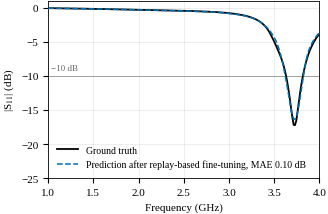

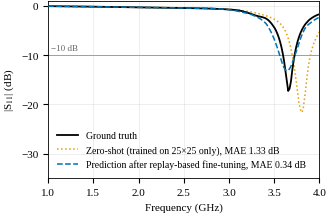

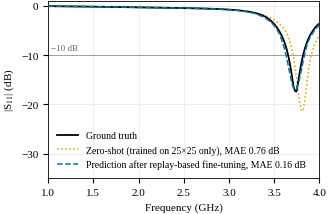

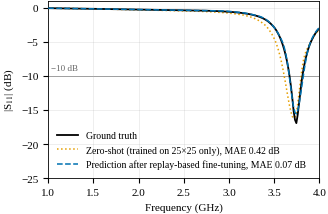

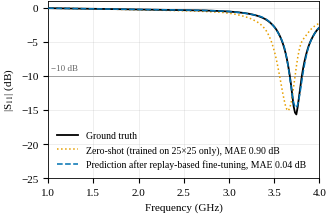

5 figures written to /content/drive/MyDrive/antenna_gnn/figures/ch48: ['ch48_25x25_single_band_deep_3p50_3p75', 'ch48_12x12_single_band_deep_3p50_3p75', 'ch48_15x15_single_band_deep_3p50_3p75', 'ch48_35x35_single_band_deep_3p50_3p75', 'ch48_45x45_single_band_deep_3p50_3p75']
legend placement: {25: 'lower left', 12: 'lower left', 15: 'lower left', 35: 'lower left', 45: 'lower left'}


In [7]:
# ── Figures: one per grid with a qualifying antenna ──
W, H = 3.5, 2.3
FD = np.linspace(1, 4, 1201)                                   # dense x for the overlap test (between the 201 samples)
def clear_of_curves(fig, ax, leg, curves, pad=3):
    fig.canvas.draw(); bb = leg.get_window_extent(fig.canvas.get_renderer())
    for c in curves:
        p = ax.transData.transform(np.column_stack([FD, np.interp(FD, F, c)]))
        if np.any((p[:, 0] >= bb.x0 - pad) & (p[:, 0] <= bb.x1 + pad) & (p[:, 1] >= bb.y0 - pad) & (p[:, 1] <= bb.y1 + pad)):
            return False
    return True
def place_legend(fig, ax, curves):
    for loc in ('lower left', 'lower right', 'center right', 'upper right'):
        leg = ax.legend(frameon=False, loc=loc, handlelength=2.2)
        if clear_of_curves(fig, ax, leg, curves):
            return loc
    for _ in range(8):                                             # no clear spot: make room below the curves
        ax.set_ylim(ax.get_ylim()[0] - 5, 1)
        for loc in ('lower left', 'lower right'):
            leg = ax.legend(frameon=False, loc=loc, handlelength=2.2)
            if clear_of_curves(fig, ax, leg, curves):
                return loc
    return loc + ' (overlap remains)'
MADE, LOCS = [], {}
for r in SEL.itertuples():
    N = r.grid; T, Pf, Pz = RES[N]; j = r.row
    fig, ax = plt.subplots(figsize=(W, H))
    ax.axhline(TAU, color='0.55', lw=0.6, ls='-', zorder=0)
    ax.text(1.03, TAU + 0.6, '−10 dB', ha='left', va='bottom', fontsize=6.5, color='0.4')
    ax.plot(F, T[j], **STYLE['gt'], zorder=3)
    if N != 25:
        ax.plot(F, Pz[j], **{**STYLE['zs'], 'label': f'{STYLE["zs"]["label"]}, MAE {r.mae_zs:.2f} dB'}, zorder=2)
    ax.plot(F, Pf[j], **{**STYLE['ft'], 'label': f'{STYLE["ft"]["label"]}, MAE {r.mae_ft:.2f} dB'}, zorder=4)
    curves = [T[j], Pf[j]] + ([Pz[j]] if N != 25 else [])
    lo = min(c.min() for c in curves)
    ax.set_xlim(1, 4); ax.set_ylim(np.floor((lo - 2) / 5) * 5, 1)
    ax.set_xlabel('Frequency (GHz)'); ax.set_ylabel('|S$_{11}$| (dB)')
    LOCS[N] = place_legend(fig, ax, curves)
    stem = f'ch48_{N}x{N}_{TAG}'
    for ext in ('pdf', 'png'):
        fig.savefig(f'{FIG}/{stem}.{ext}', dpi=600 if ext == 'png' else None)
    plt.show(); plt.close(fig); MADE.append(stem)
print(f'{len(MADE)} figures written to {FIG}:', MADE)
print('legend placement:', LOCS)

## 8. Captions and guards
**Writes:** `ch48_captions.md`. Each draft caption:
- states the three constraints
- labels the example best-case, giving its rank and the group size
- gives the group's median error

**Guards:**
- one figure per grid with a qualifying antenna, saved as PDF and PNG
- fonts embedded
- every selected antenna re-checked against all three constraints and confirmed as the lowest-error member of its group
- no 55×55
- no legend left overlapping a curve
- no earlier artifact or checkpoint modified

In [8]:
# ── Captions, guards ──
cap = ['# Chunk 48 — Deep single-band S11 figures (2.5–3.0 GHz): draft captions', '',
       f'Fine-tuned model: `{Path(MODEL_FT).name}` (one replay-fine-tuned GNN for 12/15/25/35/45). Zero-shot model: '
       '`best_model.pt` (trained on 25×25 only). Qualifying test antennas have exactly one band (a true-curve dip below '
       f'−10 dB with ≥ 3 dB prominence), whose depth is below {DEPTH_DB:.0f} dB and whose frequency lies in {F_LO}–{F_HI} GHz. '
       f'Each figure shows the qualifying antenna with the most accurate fine-tuned prediction (lowest {SELECT_METRIC.upper()}): '
       'a best-case example. The group median is given alongside.', '']
for r in SEL.itertuples():
    base = (f'**{r.grid}×{r.grid}** (`ch48_{r.grid}x{r.grid}_{TAG}`). Simulated and predicted |S11| for a {r.grid}×{r.grid} '
            f'single-band test antenna resonating at {r.dip_ghz:.2f} GHz with a {r.dip_db:.1f} dB dip; its fine-tuned prediction '
            f'is the most accurate of {r.group_size} test antenna{"s" if r.group_size != 1 else ""} meeting the same constraints. ')
    if r.grid == 25:
        base += f'Replay-fine-tuned GNN: MAE {r.mae_ft:.2f} dB, MSE {r.mse_ft:.2f} dB².'
    else:
        base += (f'Zero-shot (25×25-trained) model: MAE {r.mae_zs:.2f} dB, MSE {r.mse_zs:.2f} dB²; after replay-based fine-tuning: '
                 f'MAE {r.mae_ft:.2f} dB, MSE {r.mse_ft:.2f} dB².')
    base += f' Median over the group after fine-tuning: MAE {r.group_median_mae_ft:.2f} dB, MSE {r.group_median_mse_ft:.2f} dB².'
    if r.group_size < 5:
        base += f' (Only {r.group_size} qualifying test antenna{"s" if r.group_size != 1 else ""}: treat as illustrative.)'
    cap += [base, '']
skipped = FUNNEL.loc[FUNNEL.qualifying == 0, 'grid'].tolist()
if skipped:
    cap += [f'_No figure for {", ".join(f"{g}×{g}" for g in skipped)}: no test antenna meets all three constraints '
            '(see `ch48_funnel.csv` and `ch48_near_misses.csv`)._', '']
open(OUT('ch48_captions.md'), 'w').write('\n'.join(cap) + '\n'); print('\n'.join(cap))

fails = []
def guard(ok, msg):
    print(f"  [{'PASS' if ok else 'FAIL'}] {msg}")
    if not ok: fails.append(msg)
expected = [f'ch48_{g}x{g}_{TAG}' for g in FUNNEL.loc[FUNNEL.qualifying > 0, 'grid']]
guard(MADE == expected, f'{len(MADE)} figure(s) for {len(expected)} grid(s) with a qualifying antenna; skipped: {skipped or "none"}')
guard(all(os.path.exists(f'{FIG}/{s}.pdf') and os.path.exists(f'{FIG}/{s}.png') for s in MADE), 'every figure saved as PDF and PNG')
guard(all(b'/FontFile' in open(f'{FIG}/{s}.pdf', 'rb').read() for s in MADE), 'fonts embedded in every PDF')
ok_all = True
for r in SEL.itertuples():                                    # re-check every constraint and the argmin, independently
    T, Pf, _ = RES[r.grid]; y = T[r.row]; nb, pk = n_bands(y)
    e = ((Pf - T) ** 2).mean(1) if SELECT_METRIC == 'mse' else np.abs(Pf - T).mean(1)
    grp = [i for i, t in enumerate(T) if (lambda b: b[0] == 1 and t[b[1][0]] < DEPTH_DB
                                           and F_LO - F_TOL <= F[b[1][0]] <= F_HI + F_TOL)(n_bands(t))]
    ok_all &= (nb == 1 and y[pk[0]] < DEPTH_DB and F_LO - F_TOL <= F[pk[0]] <= F_HI + F_TOL
               and len(grp) == r.group_size and e[r.row] == min(e[i] for i in grp))
guard(ok_all, 'every selected antenna is single band, below -20 dB, in the window, and the lowest-error member of its group')
guard(not any(SEL.grid == 55) if len(SEL) else True, 'no 55x55')
guard(not any('overlap' in str(v) for v in LOCS.values()), 'no legend overlaps a curve')
guard(all(os.path.getmtime(p) == t for p, t in PRIOR.items() if os.path.exists(p)), f'no earlier artifact or checkpoint modified ({len(PRIOR)})')
assert not fails, fails
print('ALL GUARDS PASSED. No training; test predictions used for illustration only.')

# Chunk 48 — Deep single-band S11 figures (2.5–3.0 GHz): draft captions

Fine-tuned model: `ch44_ft15_from4_replay_p100_s0.pt` (one replay-fine-tuned GNN for 12/15/25/35/45). Zero-shot model: `best_model.pt` (trained on 25×25 only). Qualifying test antennas have exactly one band (a true-curve dip below −10 dB with ≥ 3 dB prominence), whose depth is below -15 dB and whose frequency lies in 3.5–3.75 GHz. Each figure shows the qualifying antenna with the most accurate fine-tuned prediction (lowest MSE): a best-case example. The group median is given alongside.

**25×25** (`ch48_25x25_single_band_deep_3p50_3p75`). Simulated and predicted |S11| for a 25×25 single-band test antenna resonating at 3.73 GHz with a -17.2 dB dip; its fine-tuned prediction is the most accurate of 924 test antennas meeting the same constraints. Replay-fine-tuned GNN: MAE 0.10 dB, MSE 0.05 dB². Median over the group after fine-tuning: MAE 0.35 dB, MSE 1.01 dB².

**12×12** (`ch48_12x12_single_band_deep_3p50_3p75`). S